# Аудит и предобработка набора данных
**Датасет:** Student Performance Factors (Kaggle, lainguyn123).  
**Задача:** регрессия — предсказание итогового балла `Exam_Score`.  


## 1 Загрузка данных и библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:

import os
print("Файл найден" if os.path.exists("StudentPerformanceFactors.csv") else "Файла нет: загрузите StudentPerformanceFactors.csv в Colab")

Файла нет: загрузите StudentPerformanceFactors.csv в Colab


In [3]:
path = "StudentPerformanceFactors.csv"
print("Файл:", path)
df = pd.read_csv(path)
df.head()

Файл: StudentPerformanceFactors.csv


FileNotFoundError: [Errno 2] No such file or directory: 'StudentPerformanceFactors.csv'

## 2.1 Исходная таблица до исправлений

Перед любыми изменениями показываем исходные данные. Это позволяет увидеть значения такими, какими они были загружены, и не путать исходную таблицу с очищенной. Ниже отображаются первые 8 строк и размер исходного датасета.

In [ ]:
# Исходные данные до очистки
display(df.head(8))
print(f'Размер исходной таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов')

## 2 Общая информация

In [ ]:
df.shape

(6607, 20)

In [ ]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [ ]:
df.describe()  # числовые признаки: среднее, медиана, квартили, min и max

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [ ]:
df.describe(exclude="number")  # категориальные: число значений, самое частое

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


## 3 Пропущенные значения

In [ ]:
df.isna().sum()  # количество пропусков по столбцам

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [ ]:
(df.isna().mean() * 100).round(2)  # доля пропусков в процентах

Hours_Studied                 0.00
Attendance                    0.00
Parental_Involvement          0.00
Access_to_Resources           0.00
Extracurricular_Activities    0.00
Sleep_Hours                   0.00
Previous_Scores               0.00
Motivation_Level              0.00
Internet_Access               0.00
Tutoring_Sessions             0.00
Family_Income                 0.00
Teacher_Quality               1.18
School_Type                   0.00
Peer_Influence                0.00
Physical_Activity             0.00
Learning_Disabilities         0.00
Parental_Education_Level      1.36
Distance_from_Home            1.01
Gender                        0.00
Exam_Score                    0.00
dtype: float64

In [ ]:
na_cols = df.columns[df.isna().any()].tolist()
print("Столбцы с пропусками:", na_cols)
print("Строк хотя бы с одним пропуском:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean() * 100:.2f}%)")

Столбцы с пропусками: ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']
Строк хотя бы с одним пропуском: 229 (3.47%)


Проверим, не связаны ли пропуски с целевой переменной: если средний балл у строк с пропуском заметно отличается, простое удаление строк может исказить данные.

In [ ]:
for col in na_cols:
    print(col)
    print(df.groupby(df[col].isna())["Exam_Score"].agg(["count", "mean"]).round(2))
    print()

Teacher_Quality
                 count   mean
Teacher_Quality              
False             6529  67.24
True                78  66.64

Parental_Education_Level
                          count   mean
Parental_Education_Level              
False                      6517  67.24
True                         90  67.06

Distance_from_Home
                    count   mean
Distance_from_Home              
False                6540  67.24
True                   67  66.43



## 4 Дубликаты

In [ ]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

np.int64(0)

In [ ]:
#df[df.duplicated(keep=False)].head(10)  # примеры, включая первые вхождения

## 5 Уникальные значения и константные признаки

In [ ]:
df.nunique()  # число уникальных непустых значений каждого столбца

Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Internet_Access                2
Tutoring_Sessions              9
Family_Income                  3
Teacher_Quality                3
School_Type                    2
Peer_Influence                 3
Physical_Activity              7
Learning_Disabilities          2
Parental_Education_Level       3
Distance_from_Home             3
Gender                         2
Exam_Score                    45
dtype: int64

In [ ]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

Series([], dtype: int64)

### Значения категориальных признаков
Проверяем опечатки, разный регистр, лишние пробелы.

In [ ]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
for c in cat_cols:
    print(c, df[c].value_counts(dropna=False).to_dict())

Parental_Involvement {'Medium': 3362, 'High': 1908, 'Low': 1337}
Access_to_Resources {'Medium': 3319, 'High': 1975, 'Low': 1313}
Extracurricular_Activities {'Yes': 3938, 'No': 2669}
Motivation_Level {'Medium': 3351, 'Low': 1937, 'High': 1319}
Internet_Access {'Yes': 6108, 'No': 499}
Family_Income {'Low': 2672, 'Medium': 2666, 'High': 1269}
Teacher_Quality {'Medium': 3925, 'High': 1947, 'Low': 657, nan: 78}
School_Type {'Public': 4598, 'Private': 2009}
Peer_Influence {'Positive': 2638, 'Neutral': 2592, 'Negative': 1377}
Learning_Disabilities {'No': 5912, 'Yes': 695}
Parental_Education_Level {'High School': 3223, 'College': 1989, 'Postgraduate': 1305, nan: 90}
Distance_from_Home {'Near': 3884, 'Moderate': 1998, 'Far': 658, nan: 67}
Gender {'Male': 3814, 'Female': 2793}


In [ ]:
# лишние пробелы в начале/конце строк
for c in cat_cols:
    s = df[c].dropna()
    n = (s != s.str.strip()).sum()
    if n:
        print(c, "— значений с лишними пробелами:", n)
print("Проверка завершена")

Проверка завершена


## 6 Целевая переменная `Exam_Score`

In [ ]:
df["Exam_Score"].describe()

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

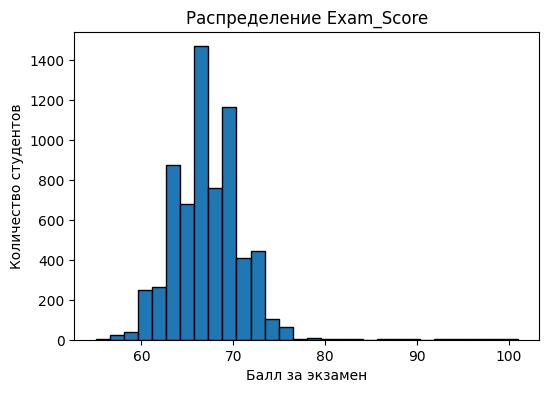

In [ ]:
df["Exam_Score"].plot(kind="hist", bins=30, edgecolor="black", figsize=(6, 4))
plt.title("Распределение Exam_Score")
plt.xlabel("Балл за экзамен")
plt.ylabel("Количество студентов")
plt.show()

В паспорте проекта предлагался порог «сдал / не сдал» ≥ 55. Проверим, есть ли у такого порога смысл на этих данных.

In [ ]:
print("Минимальный балл:", df["Exam_Score"].min())
print("Максимальный балл:", df["Exam_Score"].max())
print("Доля студентов с баллом >= 55: %.1f%%" % ((df["Exam_Score"] >= 55).mean() * 100))
print("Строк с баллом > 100:", (df["Exam_Score"] > 100).sum())

Минимальный балл: 55
Максимальный балл: 101
Доля студентов с баллом >= 55: 100.0%
Строк с баллом > 100: 1


## 7 Распределения числовых признаков

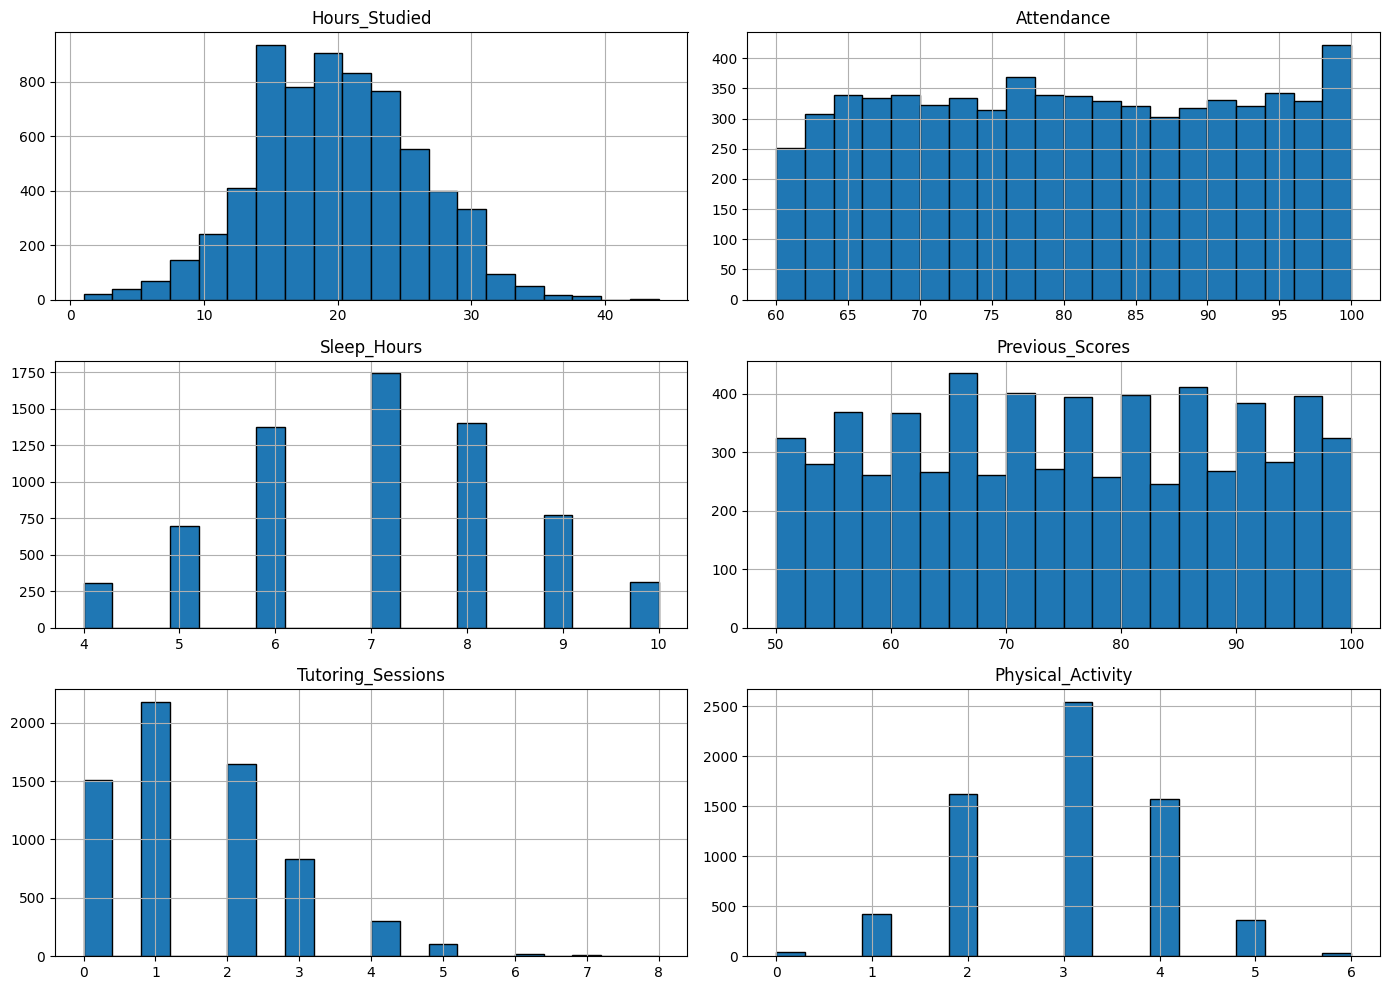

In [ ]:
numeric_df = df.select_dtypes(include="number")
features = numeric_df.drop(columns="Exam_Score", errors="ignore")
features.hist(bins=20, figsize=(14, 10), edgecolor="black")
plt.tight_layout()
plt.show()

## 8 Выбросы

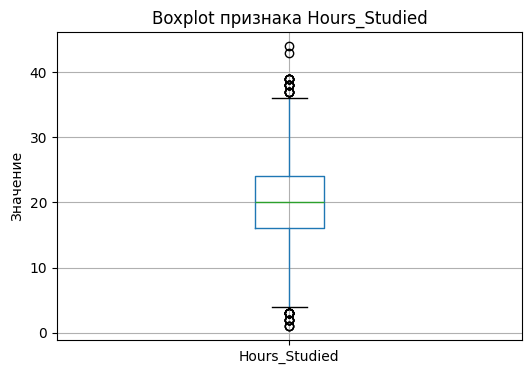

In [ ]:
column = "Hours_Studied"
df.boxplot(column=column, figsize=(6, 4))
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение")
plt.show()

Линия внутри ящика — медиана, ящик охватывает центральные 50% значений. Отдельные точки за усами — потенциальные выбросы (не обязательно ошибки).

In [ ]:
# число выбросов по правилу 1.5 * IQR для всех числовых столбцов
rows = []
for c in numeric_df.columns:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    rows.append([c, low, high, n, round(n / len(df) * 100, 2)])
pd.DataFrame(rows, columns=["признак", "нижняя граница", "верхняя граница", "выбросов", "%"])

,признак,нижняя граница,верхняя граница,выбросов,%
0,Hours_Studied,4.0,36.0,43,0.65
1,Attendance,40.0,120.0,0,0.00
2,Sleep_Hours,3.0,11.0,0,0.00
3,Previous_Scores,25.5,125.5,0,0.00
4,Tutoring_Sessions,-0.5,3.5,430,6.51
5,Physical_Activity,-1.0,7.0,0,0.00
6,Exam_Score,59.0,75.0,104,1.57


## 9 Логические проверки значений
Выход за допустимые границы — это уже не выброс, а ошибка данных.

In [ ]:
checks = {
    "Attendance вне [0, 100]":      ~df["Attendance"].dropna().between(0, 100),
    "Previous_Scores вне [0, 100]": ~df["Previous_Scores"].dropna().between(0, 100),
    "Exam_Score вне [0, 100]":      ~df["Exam_Score"].dropna().between(0, 100),
    "Sleep_Hours вне [0, 24]":      ~df["Sleep_Hours"].dropna().between(0, 24),
    "Hours_Studied < 0":            df["Hours_Studied"] < 0,
    "Tutoring_Sessions < 0":        df["Tutoring_Sessions"] < 0,
    "Physical_Activity < 0":        df["Physical_Activity"] < 0,
}
for name, mask in checks.items():
    print(f"{name}: {int(mask.sum())}")

Attendance вне [0, 100]: 0
Previous_Scores вне [0, 100]: 0
Exam_Score вне [0, 100]: 1
Sleep_Hours вне [0, 24]: 0
Hours_Studied < 0: 0
Tutoring_Sessions < 0: 0
Physical_Activity < 0: 0


## 10 Связь признаков с целевой переменной

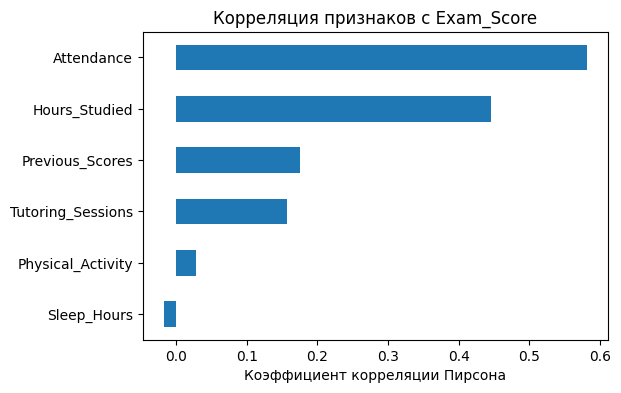

Sleep_Hours         -0.017
Physical_Activity    0.028
Tutoring_Sessions    0.157
Previous_Scores      0.175
Hours_Studied        0.445
Attendance           0.581
Name: Exam_Score, dtype: float64

In [ ]:
corr = numeric_df.corr()["Exam_Score"].drop("Exam_Score").sort_values()
corr.plot(kind="barh", figsize=(6, 4))
plt.title("Корреляция признаков с Exam_Score")
plt.xlabel("Коэффициент корреляции Пирсона")
plt.show()
corr.round(3)

## 11 Краткий итог аудита

In [ ]:
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Строк с пропусками:", df.isna().any(axis=1).sum())
print("Полных копий:", df.duplicated().sum())
print("Строк с Exam_Score > 100:", (df["Exam_Score"] > 100).sum())

Количество строк: 6607
Количество столбцов: 20
Пропущенных ячеек: 235
Строк с пропусками: 229
Полных копий: 0
Строк с Exam_Score > 100: 1


## 12 Предобработка данных

Решения (обоснование):
- **Пропуски** в `Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home` — категориальные, их мало; удалять строки не хочется, поэтому заполняем **модой** (самым частым значением).
- **Exam_Score > 100** — выход за максимально возможный балл, считаем ошибкой; значение обрезаем до 100.
- **Выбросы** в `Hours_Studied` и т. п. — значения реалистичны, **оставляем**.
- Дубликаты — удаляем, если найдены.

In [ ]:
df_clean = df.copy()

# 1) дубликаты
df_clean = df_clean.drop_duplicates()

# 2) пропуски в категориальных столбцах -> мода
for col in df_clean.columns[df_clean.isna().any()]:
    mode_value = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_value)
    print(f"{col}: заполнено значением '{mode_value}'")

# 3) нелогичные значения целевой переменной
df_clean["Exam_Score"] = df_clean["Exam_Score"].clip(upper=100)

Teacher_Quality: заполнено значением 'Medium'
Parental_Education_Level: заполнено значением 'High School'
Distance_from_Home: заполнено значением 'Near'


## 13 Проверка после очистки

In [ ]:
print("Было:", df.shape, "-> стало:", df_clean.shape)
print("Пропусков осталось:", df_clean.isna().sum().sum())
print("Дубликатов осталось:", df_clean.duplicated().sum())
print("Максимальный Exam_Score:", df_clean["Exam_Score"].max())

Было: (6607, 20) -> стало: (6607, 20)
Пропусков осталось: 0
Дубликатов осталось: 0
Максимальный Exam_Score: 100


In [ ]:
df_clean.to_csv("student_performance_clean.csv", index=False)
print("Сохранено: student_performance_clean.csv")

Сохранено: student_performance_clean.csv


## 14 Выводы

- **Размер данных:** 6607 строк, 20 столбцов (7 числовых, 13 категориальных). Константных признаков нет.
- **Пропуски:** 235 ячеек в трёх категориальных столбцах — `Teacher_Quality` (78, 1.18%), `Parental_Education_Level` (90, 1.36%), `Distance_from_Home` (67, 1.01%). Затронуто 229 строк (3.47%). Средний `Exam_Score` у строк с пропусками почти не отличается от остальных (66.4–67.1 против 67.2), поэтому пропуски заполнены модой, строки не удалялись.
- **Дубликаты:** 0.
- **Опечатки и пробелы в категориях:** не найдены.
- **Нелогичные значения:** одна строка с `Exam_Score` = 101 (максимум шкалы 100) — обрезана до 100. Остальные границы (посещаемость, прошлые баллы, сон, неотрицательные счётчики) соблюдены.
- **Выбросы:** `Hours_Studied` — 43 строки (0.65%), `Tutoring_Sessions` — 430 (6.51%), `Exam_Score` — 104 (1.57%). Значения реалистичны, оставлены.
- **Целевая переменная:** диапазон 55–101, среднее 67.2, медиана 67, стандартное отклонение 3.9. Порог «сдал / не сдал» ≥ 55 из паспорта проекта **не подходит**: его проходят 100% студентов. Для классификации нужен другой порог (например, медиана) либо остаётся только регрессия.
- **Связь с целью (корреляция Пирсона):** `Attendance` 0.58, `Hours_Studied` 0.45, `Previous_Scores` 0.18, `Tutoring_Sessions` 0.16, `Physical_Activity` 0.03, `Sleep_Hours` −0.02. Часы сна практически не связаны с баллом, что полезно для исследовательского вопроса.
- **Ограничение:** данные синтетические, выводы нельзя переносить на реальных студентов.